# Cap. 2: Statistical Learning aplicado a WDO e WIN

**Objetivo:** levar os conceitos das aulas 2.1 a 2.4 para os dados reais, usando só as ferramentas do capítulo (KNN e regressão linear).

| Aula | Pergunta aqui |
|---|---|
| 2.1 Modelos de regressão | Quanto do retorno do próximo minuto é **redutível**? A resposta muda se o alvo é a *direção* ou a *intensidade* do movimento? |
| 2.2 Dimensionalidade | O que acontece com o KNN quando entram features inúteis? |
| 2.3 Viés-variância | Como o erro de treino e o de teste mudam com a **flexibilidade** do modelo? Quanto do erro é viés e quanto é variância? |
| 2.4 Classificação | Um classificador KNN bate o chute ingênuo? Quão longe fica do **classificador de Bayes**? |

**Dados:** barras de 1 minuto do vencimento principal (ver [notebook 00](00_exploracao_wdo_win.ipynb)). **Treino:** os 14 primeiros pregões. **Teste:** os 6 últimos. A divisão é por data, nunca por sorteio: sortear minutos colocaria o futuro no treino (ver *walk-forward* no [glossário](../GLOSSARIO.md)).

Os conceitos usados estão no [glossário](../GLOSSARIO.md#aprendizado-estatístico-islp-cap-2).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.pipeline import load
from src.features import add_forward_return, add_lags

plt.rcParams["figure.figsize"] = (11, 4)
rng = np.random.default_rng(42)

## 0. Features e alvos

Tudo o que entra como **X** é conhecido no fechamento do minuto *t*. O **Y** é o que acontece no minuto *t+1*.

| Coluna | O que é |
|---|---|
| `ret`, `ret_l1`, `ret_l2` | log-retorno do minuto atual e dos dois anteriores, em bps |
| `abs_ret`, `abs_ret_l1`, `abs_ret_l2` | o mesmo em valor absoluto (intensidade do movimento) |
| `imbalance` | desequilíbrio de agressão estimado pela tick rule |
| `log_vol` | log do volume do minuto |
| `minuto` | minutos desde as 9h |
| **`fwd`** (alvo) | retorno do próximo minuto, em bps: a **direção** |
| **`abs_fwd`** (alvo) | \|retorno do próximo minuto\|: a **intensidade** |

Defasagens e alvos não atravessam a noite nem os leilões (`trading_segments`).

In [2]:
FEATURES = ["ret", "ret_l1", "ret_l2", "abs_ret", "abs_ret_l1", "abs_ret_l2", "imbalance", "log_vol", "minuto"]


def montar(b):
    b = add_forward_return(b.drop(columns="root"), 1)
    b["ret"] = b["ret"] * 1e4
    b["fwd"] = b["fwd_ret_1"] * 1e4
    b["abs_ret"], b["abs_fwd"] = b["ret"].abs(), b["fwd"].abs()
    b = add_lags(add_lags(b, "ret", 2), "abs_ret", 2)
    b["log_vol"] = np.log(b["volume"])
    b["minuto"] = (b.index.hour - 9) * 60 + b.index.minute
    return b.dropna(subset=FEATURES + ["fwd"])


dados = {r: montar(g) for r, g in load("bars_1min").groupby("root")}
dias = sorted(dados["WDO"].index.normalize().unique())
corte = dias[14]
treino = {r: d[d.index < corte] for r, d in dados.items()}
teste = {r: d[d.index >= corte] for r, d in dados.items()}

pd.DataFrame({r: {"treino": f"{treino[r].index[0]:%d/%m} a {treino[r].index[-1]:%d/%m} ({len(treino[r]):,} min)",
                  "teste": f"{teste[r].index[0]:%d/%m} a {teste[r].index[-1]:%d/%m} ({len(teste[r]):,} min)"}
              for r in dados})

,WDO,WIN
treino,"20/10 a 09/11 (7,903 min)","20/10 a 09/11 (7,831 min)"
teste,"10/11 a 17/11 (3,396 min)","10/11 a 17/11 (3,362 min)"


Medida de erro usada em todo o notebook: **MSE relativo** = MSE do modelo / MSE do chute ingênuo (prever sempre a média do treino).
- **< 1:** o modelo acrescenta informação.
- **= 1:** empata com não saber nada.
- **> 1:** atrapalha.

1 − MSE relativo é o **R² fora da amostra**.

In [3]:
def mse_rel(modelo, cols, alvo, root, base=None):
    tr, te = treino[root], teste[root]
    modelo.fit(tr[cols], tr[alvo])
    ingenuo = ((te[alvo] - tr[alvo].mean()) ** 2).mean()
    return ((te[alvo] - modelo.predict(te[cols])) ** 2).mean() / ingenuo


def knn(k):
    return make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))

## 1. f(X) e erro irredutível (aula 2.1)

$Y = f(X) + \varepsilon$, com $f(x) = E[Y \mid X = x]$. A forma mais direta de estimar $f$ é a das aulas: **para cada x, tirar a média do Y dos vizinhos mais próximos**.

Comparamos dois alvos, cada um com a feature que parece mais natural para ele:
- **direção** (`fwd`) contra `imbalance`: o fluxo de agressão do minuto indica para onde vai o próximo?
- **intensidade** (`abs_fwd`) contra `abs_ret`: um minuto agitado é seguido de outro minuto agitado?

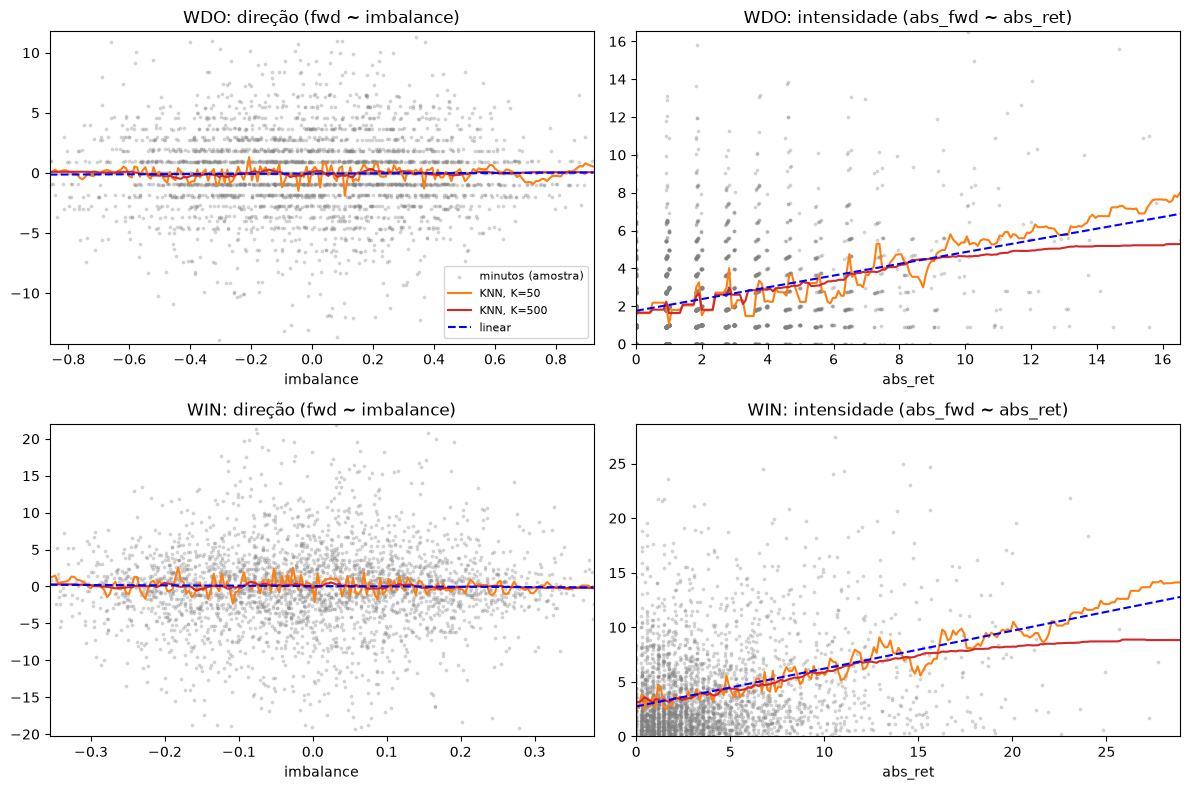

In [4]:
pares = [("imbalance", "fwd", "direção"), ("abs_ret", "abs_fwd", "intensidade")]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, root in enumerate(dados):
    tr = treino[root]
    for j, (x, y, nome) in enumerate(pares):
        ax = axes[i, j]
        lo, hi = tr[x].quantile([0.005, 0.995])
        amostra = tr.sample(3000, random_state=0)
        ax.scatter(amostra[x], amostra[y], s=3, alpha=0.25, color="gray", label="minutos (amostra)")
        grade = pd.DataFrame({x: np.linspace(lo, hi, 200)})
        for k, cor in [(50, "tab:orange"), (500, "tab:red")]:
            ax.plot(grade[x], KNeighborsRegressor(k).fit(tr[[x]], tr[y]).predict(grade), color=cor, label=f"KNN, K={k}")
        ax.plot(grade[x], LinearRegression().fit(tr[[x]], tr[y]).predict(grade), "b--", label="linear")
        ax.set_xlim(lo, hi)
        ax.set_ylim(*tr[y].quantile([0.005, 0.995]))
        ax.set_title(f"{root}: {nome} ({y} ~ {x})")
        ax.set_xlabel(x)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()

In [5]:
rows = []
for root in dados:
    for x, y, nome in pares:
        rows.append({"ativo": root, "alvo": nome, "feature": x,
                     "desvio-padrão do alvo (bps)": teste[root][y].std(),
                     "R² fora da amostra, linear (%)": 100 * (1 - mse_rel(LinearRegression(), [x], y, root)),
                     "R² fora da amostra, KNN K=500 (%)": 100 * (1 - mse_rel(KNeighborsRegressor(500), [x], y, root))})
pd.DataFrame(rows).set_index(["ativo", "alvo"]).round(2)

feature  desvio-padrão do alvo (bps)  \
ativo alvo                                                  
WDO   direção      imbalance                         3.02   
      intensidade    abs_ret                         2.16   
WIN   direção      imbalance                         3.76   
      intensidade    abs_ret                         2.61   

                   R² fora da amostra, linear (%)  \
ativo alvo                                          
WDO   direção                               -0.08   
      intensidade                            6.23   
WIN   direção                                0.01   
      intensidade                           14.78   

                   R² fora da amostra, KNN K=500 (%)  
ativo alvo                                            
WDO   direção                                  -0.45  
      intensidade                               7.07  
WIN   direção                                  -0.52  
      intensidade                              15.44

**O que os números mostram**
- **Direção:** a curva estimada de $f$ é praticamente plana em zero. O R² fora da amostra é ~0 na linear e negativo no KNN. Com essa feature, quase todo o erro é **irredutível**.
- **Intensidade:** $f$ cresce com `abs_ret`, ou seja, minuto agitado tende a ser seguido de minuto agitado. Com uma única feature, o R² fora da amostra fica em 6–7% no WDO e ~15% no WIN. É a aglomeração de volatilidade do notebook 00 virando previsão.
- No WDO os pontos formam faixas porque o preço anda em ticks de 0,5 ponto (~0,9 bp), então |ret| só assume alguns valores.

"Irredutível" é sempre **relativo ao X escolhido**. Com outra informação (o livro de ofertas, por exemplo), parte desse erro poderia virar redutível. No mesmo mercado e com features parecidas, um alvo é quase todo irredutível e o outro é parcialmente redutível: escolher o alvo já faz parte da modelagem.

## 2. Maldição da dimensionalidade (aula 2.2)

O KNN só funciona se houver vizinhos *perto* de cada ponto. Cada feature nova é uma dimensão a mais, e em muitas dimensões até os vizinhos mais próximos ficam longe.

**Experimento:** alvo = intensidade (`abs_fwd`), uma feature útil (`abs_ret`) e *m* features de puro ruído aleatório. O KNN dá o mesmo peso a todas as dimensões. A regressão linear é um modelo **estruturado**: ela consegue dar coeficiente ~0 ao ruído.

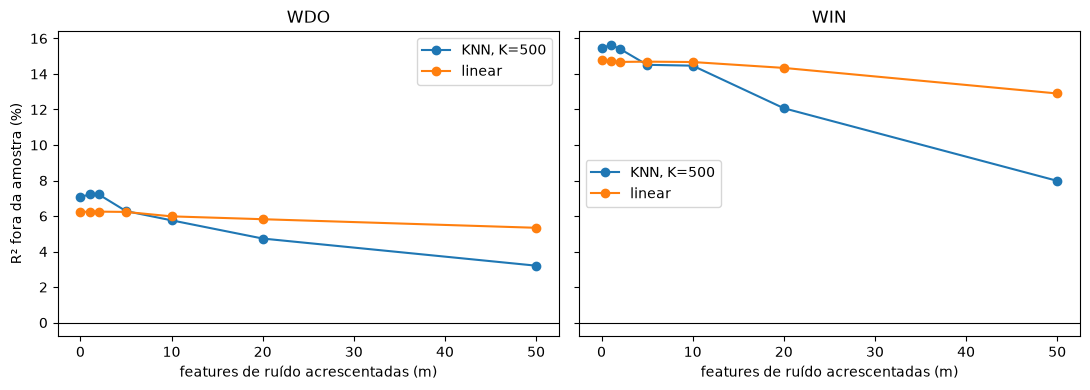

In [6]:
ms = [0, 1, 2, 5, 10, 20, 50]
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, root in zip(axes, dados):
    tr, te = treino[root].copy(), teste[root].copy()
    for i in range(max(ms)):
        tr[f"ruido{i}"], te[f"ruido{i}"] = rng.standard_normal(len(tr)), rng.standard_normal(len(te))
    treino_bkp, teste_bkp = treino[root], teste[root]
    treino[root], teste[root] = tr, te
    res = {}
    for m in ms:
        cols = ["abs_ret"] + [f"ruido{i}" for i in range(m)]
        res[m] = {"KNN, K=500": 100 * (1 - mse_rel(knn(500), cols, "abs_fwd", root)),
                  "linear": 100 * (1 - mse_rel(make_pipeline(StandardScaler(), LinearRegression()), cols, "abs_fwd", root))}
    treino[root], teste[root] = treino_bkp, teste_bkp
    pd.DataFrame(res).T.plot(ax=ax, marker="o", title=root)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("features de ruído acrescentadas (m)")
axes[0].set_ylabel("R² fora da amostra (%)")
plt.tight_layout()

**O que os números mostram**
- O KNN perde R² conforme o ruído entra: de 7,1% para 3,2% no WDO e de 15,4% para 8,0% no WIN, com 50 features de ruído. A linear quase não se mexe: de 6,2% para 5,3% e de 14,8% para 12,9%.
- **Por quê:** o KNN mede a distância em todas as dimensões com o mesmo peso. Com 50 dimensões de ruído, os "vizinhos" passam a ser escolhidos quase só pelo ruído. A linear estima um coeficiente por feature e dá ~0 ao ruído. Ela perde um pouco porque cada coeficiente estimado carrega alguma variância.
- Com uma feature, o KNN é igual ou melhor que a linear, porque capta a curvatura. Com muitas, a linear ganha. É o trade-off da aula 2.2 entre modelo **estruturado** (paramétrico) e modelo **flexível**.
- A pequena melhora do KNN com 1 ou 2 features de ruído é variação de amostra, não um efeito real.

## 3. Flexibilidade, erro de treino e erro de teste (aula 2.3)

No KNN, a flexibilidade é controlada por K. **K pequeno** (média de poucos vizinhos) segue cada detalhe dos dados: é muito flexível. **K grande** suaviza tudo: é pouco flexível. O eixo horizontal usa 1/K, então a flexibilidade cresce para a direita, como nos gráficos do livro.

Aqui o modelo usa as 9 features. A linha tracejada é a regressão linear com as mesmas features.

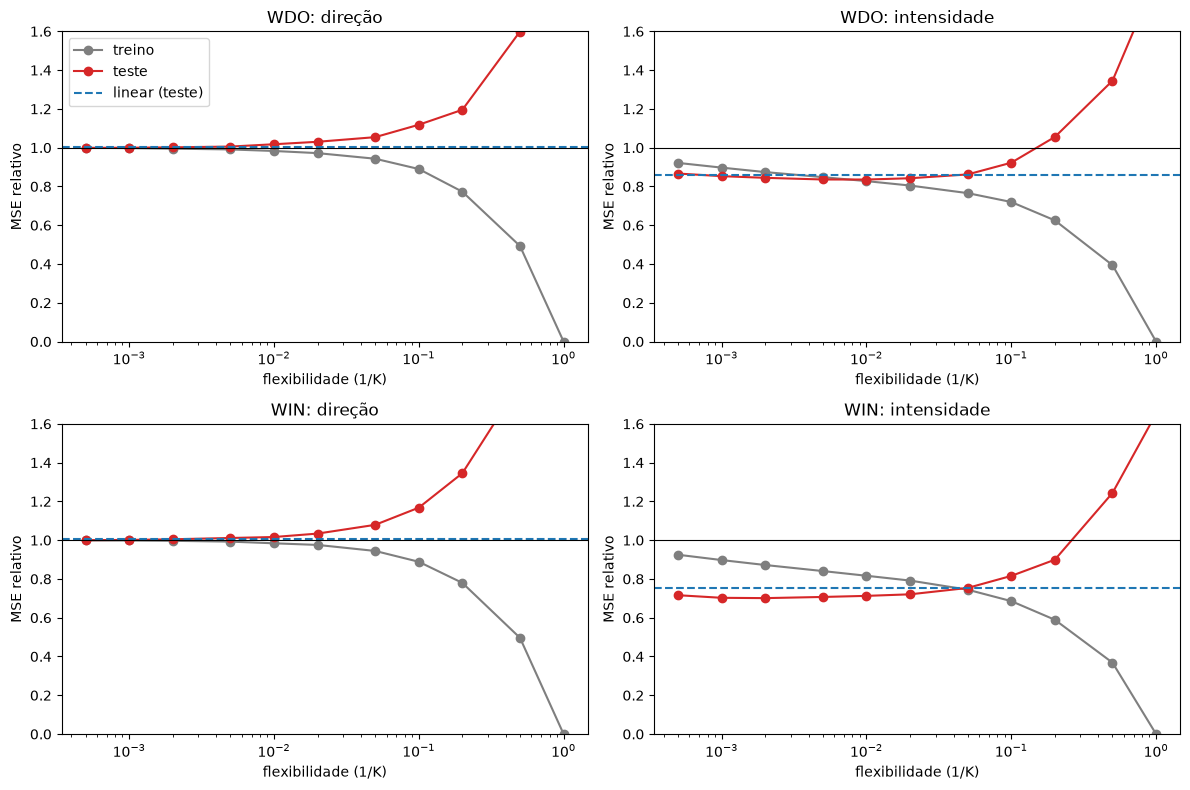

In [7]:
Ks = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
curvas = {}
for i, root in enumerate(dados):
    tr, te = treino[root], teste[root]
    for j, (alvo, nome) in enumerate([("fwd", "direção"), ("abs_fwd", "intensidade")]):
        ingenuo_tr = tr[alvo].var(ddof=0)
        ingenuo_te = ((te[alvo] - tr[alvo].mean()) ** 2).mean()
        rows = {}
        for k in Ks:
            m = knn(k).fit(tr[FEATURES], tr[alvo])
            rows[k] = {"treino": ((tr[alvo] - m.predict(tr[FEATURES])) ** 2).mean() / ingenuo_tr,
                       "teste": ((te[alvo] - m.predict(te[FEATURES])) ** 2).mean() / ingenuo_te}
        c = pd.DataFrame(rows).T
        curvas[(root, nome)] = c
        ax = axes[i, j]
        ax.plot(1 / c.index, c["treino"], "o-", color="tab:gray", label="treino")
        ax.plot(1 / c.index, c["teste"], "o-", color="tab:red", label="teste")
        ax.axhline(mse_rel(LinearRegression(), FEATURES, alvo, root), color="tab:blue", ls="--", label="linear (teste)")
        ax.axhline(1, color="k", lw=0.8)
        ax.set_xscale("log")
        ax.set_ylim(0, 1.6)
        ax.set_title(f"{root}: {nome}")
        ax.set_xlabel("flexibilidade (1/K)")
        ax.set_ylabel("MSE relativo")
axes[0, 0].legend()
plt.tight_layout()

In [8]:
melhor = pd.DataFrame({f"{r} · {n}": {"K com menor erro de teste": c["teste"].idxmin(),
                                         "R² fora da amostra no melhor K (%)": 100 * (1 - c["teste"].min()),
                                         "R² fora da amostra com K=1 (%)": 100 * (1 - c.loc[1, "teste"])}
                       for (r, n), c in curvas.items()}).T
melhor.round(2)

,K com menor erro de teste,R² fora da amostra no melhor K (%),R² fora da amostra com K=1 (%)
WDO · direção,2000.0,0.17,-115.75
WDO · intensidade,100.0,16.43,-87.48
WIN · direção,2000.0,0.01,-148.53
WIN · intensidade,500.0,29.89,-65.22


**O que os números mostram**
- **Treino:** o MSE de treino sempre cai com a flexibilidade e chega a zero com K=1, porque cada ponto é vizinho de si mesmo. Erro de treino não serve para escolher modelo.
- **Teste, direção:** o melhor é o modelo menos flexível (K=2.000), e mesmo assim o R² fica em ~0. Qualquer flexibilidade só piora: com K=1, o R² é de −116% no WDO e −149% no WIN. A linear empata com o chute ingênuo.
- **Teste, intensidade:** aparece o "U" das aulas, com ótimo em K entre 100 e 500. O R² chega a 16% no WDO e 30% no WIN, acima do da seção 1 porque agora entram horário e volume. A linear fica um pouco atrás, com ~14% e ~25%.
- No WIN (intensidade), o erro de teste fica *abaixo* do de treino nos K grandes. O período de teste foi mais calmo e não tem um dia como 26/10, que está no treino. Isso é uma **mudança de regime**: cada curva está normalizada pelo próprio chute ingênuo, mas os dois períodos não são iguais.
- ⚠️ O melhor K foi escolhido olhando o teste, o que deixa os números otimistas. Escolher K sem olhar o teste é o assunto do cap. 5.

### 3.1 Decompondo o erro em viés² + variância + irredutível

Com dados reais não dá para separar viés e variância, porque o $f$ verdadeiro é desconhecido. A saída é uma **simulação** em que $f$ é conhecido, mas o mais realista possível:
- **X:** valores reais da feature (WIN, período de treino);
- **f verdadeiro:** o $f$ estimado na seção 1 (linear para a direção, KNN K=500 para a intensidade);
- **ε:** resíduos reais sorteados com reposição, o que preserva as caudas gordas.

Repetimos 200 vezes: sorteia um conjunto de treino de 2.000 minutos, ajusta o modelo e prevê em 300 pontos fixos. Em cada ponto, o **viés** é a diferença entre a previsão média e o $f$ verdadeiro, e a **variância** é o quanto a previsão muda de um conjunto de treino para outro.

Simplificação: os resíduos são sorteados independentemente de X. Nos dados reais, minutos agitados têm resíduos maiores.

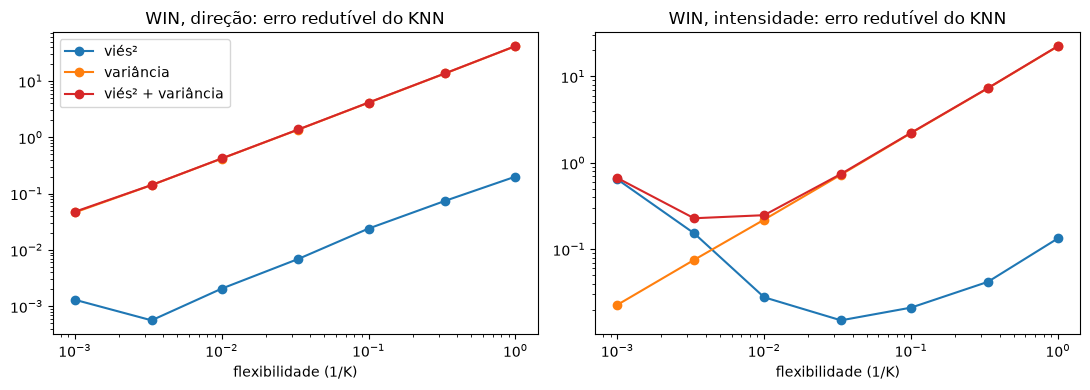

In [9]:
def decompor(x, f_x, eps, Ks, n=2000, reps=200, n_pontos=300):
    idx0 = rng.choice(len(x), n_pontos, replace=False)
    x0, f0 = x[idx0].reshape(-1, 1), f_x[idx0]
    modelos = {f"KNN K={k}": (lambda k=k: KNeighborsRegressor(k)) for k in Ks}
    modelos["linear"] = LinearRegression
    prev = {nome: np.empty((reps, n_pontos)) for nome in modelos}
    for r in range(reps):
        i = rng.choice(len(x), n)
        xs, ys = x[i].reshape(-1, 1), f_x[i] + rng.choice(eps, n)
        for nome, cria in modelos.items():
            prev[nome][r] = cria().fit(xs, ys).predict(x0)
    out = {nome: {"viés²": ((p.mean(0) - f0) ** 2).mean(), "variância": p.var(0).mean()} for nome, p in prev.items()}
    out = pd.DataFrame(out).T
    out["irredutível"] = eps.var()
    out["erro de teste esperado"] = out.sum(axis=1)
    return out


tr = treino["WIN"]
Ks_sim = [1, 3, 10, 30, 100, 300, 1000]
decomp = {}
for x, y, nome in pares:
    xv, yv = tr[x].to_numpy(), tr[y].to_numpy()
    verdadeiro = (LinearRegression() if nome == "direção" else KNeighborsRegressor(500)).fit(xv.reshape(-1, 1), yv)
    f_x = verdadeiro.predict(xv.reshape(-1, 1))
    decomp[nome] = decompor(xv, f_x, yv - f_x, Ks_sim)

fig, axes = plt.subplots(1, 2)
for ax, (nome, d) in zip(axes, decomp.items()):
    knn_d = d.drop(index="linear")
    flex = 1 / np.array(Ks_sim)
    ax.plot(flex, knn_d["viés²"], "o-", label="viés²")
    ax.plot(flex, knn_d["variância"], "o-", label="variância")
    ax.plot(flex, knn_d["viés²"] + knn_d["variância"], "o-", color="tab:red", label="viés² + variância")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"WIN, {nome}: erro redutível do KNN")
    ax.set_xlabel("flexibilidade (1/K)")
axes[0].legend()
plt.tight_layout()

In [10]:
pd.concat(decomp).round(4)

viés²  variância  irredutível  erro de teste esperado
direção     KNN K=1     0.2008    41.6650      42.0925                 83.9582
            KNN K=3     0.0748    13.7008      42.0925                 55.8680
            KNN K=10    0.0240     4.1274      42.0925                 46.2438
            KNN K=30    0.0069     1.3772      42.0925                 43.4766
            KNN K=100   0.0021     0.4195      42.0925                 42.5141
            KNN K=300   0.0006     0.1418      42.0925                 42.2349
            KNN K=1000  0.0013     0.0463      42.0925                 42.1401
            linear      0.0002     0.0434      42.0925                 42.1361
intensidade KNN K=1     0.1338    22.3332      22.0100                 44.4770
            KNN K=3     0.0420     7.2884      22.0100                 29.3404
            KNN K=10    0.0211     2.2081      22.0100                 24.2392
            KNN K=30    0.0150     0.7291      22.0100                 22.7541
            KNN K=100   0.0278     0.2201      22.0100                 22.2580
            KNN K=300   0.1531     0.0753      22.0100                 22.2385
            KNN K=1000  0.6456     0.0227      22.0100                 22.6783
            linear      0.4840     0.0402      22.0100                 22.5342

**O que os números mostram** (unidade: bps²)
- **Direção:** o viés² é minúsculo em qualquer K, porque o $f$ verdadeiro é quase plano. O erro redutível é praticamente só variância, e a variância cai com K. O melhor é o modelo mais rígido: KNN com K=1.000 ou a linear, com 42,14 contra um irredutível de 42,09. **Quando não há sinal, flexibilidade é só custo.**
- **Intensidade:** o "U" clássico. Indo de K=1.000 para K=30, o viés² cai de 0,65 para 0,015, mas a variância sobe de 0,02 para 0,73 (e chega a 22 com K=1). A soma é mínima em K entre 100 e 300. A linear tem viés² de 0,48 porque o $f$ verdadeiro é curvo (ele achata nos |ret| altos, ver gráfico da seção 1) e uma reta não acompanha a curva.
- **Escala:** nos dois casos, o erro irredutível (42 e 22) é cem vezes maior que viés² + variância no melhor modelo (< 0,3). Em mercado, o teto de quanto um modelo pode melhorar é dado pelo erro irredutível, não pelo modelo.

## 4. Classificação (aula 2.4)

Duas perguntas de classificação para o próximo minuto:
- **direção:** sobe, fica parado ou cai?
- **agitado:** o |retorno| vai ficar acima da mediana do treino?

A medida é a **taxa de erro** no teste (fração de classificações erradas), comparada com o **chute ingênuo**: prever sempre a classe mais comum no treino.

⚠️ O "melhor K" das tabelas foi escolhido olhando o próprio teste, o que deixa o resultado otimista. O certo é escolher K num conjunto de validação separado, que é o assunto do cap. 5.

In [11]:
def classes(d, mediana_treino):
    return {"direção": np.sign(d["fwd"]).map({1: "sobe", 0: "parado", -1: "cai"}),
            "agitado": (d["abs_fwd"] > mediana_treino).map({True: "agitado", False: "calmo"})}


rows, curvas_cls = [], {}
for root in dados:
    tr, te = treino[root], teste[root]
    med = tr["abs_fwd"].median()
    y_tr, y_te = classes(tr, med), classes(te, med)
    for tarefa in ["direção", "agitado"]:
        freq = y_tr[tarefa].value_counts(normalize=True)
        ingenuo = (y_te[tarefa] != freq.idxmax()).mean()
        erros = {}
        for k in Ks[1:]:
            m = make_pipeline(StandardScaler(), KNeighborsClassifier(k)).fit(tr[FEATURES], y_tr[tarefa])
            erros[k] = {"treino": (m.predict(tr[FEATURES]) != y_tr[tarefa]).mean(),
                        "teste": (m.predict(te[FEATURES]) != y_te[tarefa]).mean()}
        c = pd.DataFrame(erros).T
        curvas_cls[(root, tarefa)] = (c, ingenuo)
        rows.append({"ativo": root, "tarefa": tarefa,
                     "classes no treino (%)": ", ".join(f"{cl} {100 * p:.0f}" for cl, p in freq.items()),
                     "erro do chute ingênuo (%)": 100 * ingenuo,
                     "melhor K": c["teste"].idxmin(),
                     "erro do KNN no melhor K (%)": 100 * c["teste"].min()})
pd.DataFrame(rows).set_index(["ativo", "tarefa"]).round(1)

classes no treino (%)  erro do chute ingênuo (%)  \
ativo tarefa                                                           
WDO   direção  sobe 42, cai 42, parado 16                       55.9   
      agitado        calmo 50, agitado 50                       35.1   
WIN   direção   sobe 49, cai 48, parado 3                       50.7   
      agitado        calmo 50, agitado 50                       36.5   

               melhor K  erro do KNN no melhor K (%)  
ativo tarefa                                          
WDO   direção      1000                         56.4  
      agitado      2000                         33.3  
WIN   direção      1000                         49.2  
      agitado      1000                         34.0

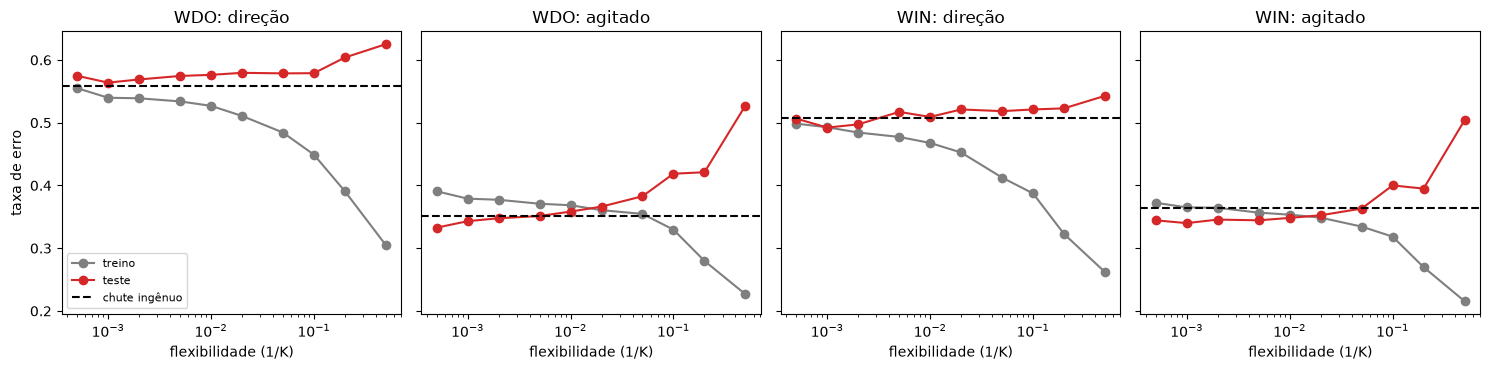

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, ((root, tarefa), (c, ingenuo)) in zip(axes, curvas_cls.items()):
    ax.plot(1 / c.index, c["treino"], "o-", color="tab:gray", label="treino")
    ax.plot(1 / c.index, c["teste"], "o-", color="tab:red", label="teste")
    ax.axhline(ingenuo, color="k", ls="--", label="chute ingênuo")
    ax.set_xscale("log")
    ax.set_title(f"{root}: {tarefa}")
    ax.set_xlabel("flexibilidade (1/K)")
axes[0].set_ylabel("taxa de erro")
axes[0].legend(fontsize=8)
plt.tight_layout()

**O que os números mostram**
- **Direção:** no WDO, o KNN (56,4% de erro) não bate o chute ingênuo (55,9%). No WIN, a diferença é de 1,5 ponto (49,2% contra 50,7%) em ~3.400 minutos. Isso está dentro do ruído (o erro-padrão de uma taxa assim é ~0,9 ponto), e o K foi escolhido no teste. Não é evidência de sinal.
- O WDO tem 16% de minutos "parados", contra só 3% no WIN: o tick do WDO é grande em relação aos movimentos de 1 minuto.
- **Agitado:** o KNN acerta um pouco mais que o chute ingênuo (33,3% contra 35,1% no WDO; 34,0% contra 36,5% no WIN). Se as classes são 50/50 no treino, por que o chute ingênuo erra só ~35%? Porque o teste foi mais calmo: só ~35% dos minutos do teste ficaram acima da mediana do treino, e o chute "sempre calmo" se beneficiou da mudança de regime.
- O ganho em classificação parece pequeno perto do R² de 16–30% da regressão. Uma explicação provável é que cortar na mediana joga fora a informação de magnitude, e muitos minutos ficam perto da fronteira entre as classes.
- As curvas repetem o padrão da regressão: o erro de treino cai com a flexibilidade e o de teste sobe.

### 4.1 O classificador de Bayes

O classificador de Bayes escolhe a classe mais provável dado X. Ele tem o **menor erro possível** (o *erro de Bayes*), mas exige conhecer $P(Y \mid X)$, que nos dados reais é desconhecido.

Na simulação, ele é conhecido. A tarefa é "agitado" no WIN, com X = `abs_ret`, e a probabilidade verdadeira $p(x)$ vem de um KNN suavizado (K=500) nos dados reais. Sorteamos rótulos com essa probabilidade, treinamos o KNN em 2.000 minutos e medimos o erro em 200.000.

,KNN K=1,KNN K=3,KNN K=10,KNN K=30,KNN K=100,KNN K=300,KNN K=1000,Bayes,ingênuo
erro (%),48.6,47.8,45.7,43.9,42.3,42.0,42.7,41.9,49.7


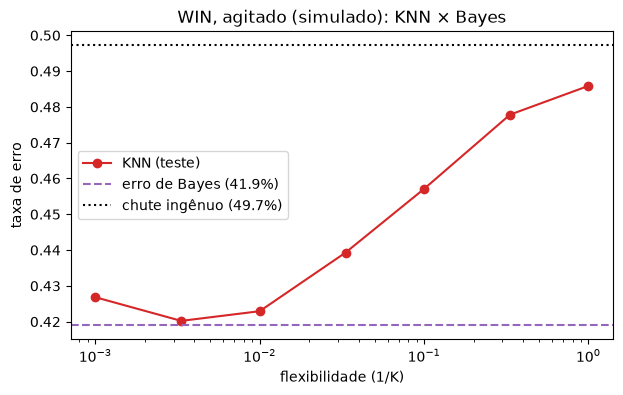

In [13]:
tr = treino["WIN"]
x = tr[["abs_ret"]].to_numpy()
y_real = (tr["abs_fwd"] > tr["abs_fwd"].median()).astype(int)
p = KNeighborsRegressor(500).fit(x, y_real).predict(x)   # P(agitado | x) "verdadeira"

i_tr, i_te = rng.choice(len(x), 2000), rng.choice(len(x), 200_000)
y_tr_sim, y_te_sim = rng.random(2000) < p[i_tr], rng.random(200_000) < p[i_te]
erro_bayes = ((p[i_te] > 0.5) != y_te_sim).mean()   # Bayes: escolhe a classe com p > 0,5
erro_ingenuo = min(y_te_sim.mean(), 1 - y_te_sim.mean())

sim = {k: (KNeighborsClassifier(k).fit(x[i_tr], y_tr_sim).predict(x[i_te]) != y_te_sim).mean() for k in Ks_sim}
ax = pd.Series(sim, name="KNN (teste)").rename(lambda k: 1 / k).plot(marker="o", logx=True, color="tab:red", figsize=(7, 4))
ax.axhline(erro_bayes, color="tab:purple", ls="--", label=f"erro de Bayes ({100 * erro_bayes:.1f}%)")
ax.axhline(erro_ingenuo, color="k", ls=":", label=f"chute ingênuo ({100 * erro_ingenuo:.1f}%)")
ax.set_xlabel("flexibilidade (1/K)")
ax.set_ylabel("taxa de erro")
ax.set_title("WIN, agitado (simulado): KNN × Bayes")
ax.legend()
pd.Series({f"KNN K={k}": 100 * e for k, e in sim.items()} | {"Bayes": 100 * erro_bayes, "ingênuo": 100 * erro_ingenuo}).round(1).to_frame("erro (%)").T

**O que os números mostram**
- O KNN nunca fica abaixo do erro de Bayes (41,9%), que é o mínimo possível com essa X. O melhor K (300) chega a 42,0%, quase lá. Com K=1, o erro vai a 48,6%, perto do chute ingênuo (49,7%).
- Mesmo o classificador perfeito erra 42%. Com essa X, a probabilidade de o próximo minuto ser agitado raramente se afasta muito de 50%. Esse é o **erro irredutível** da classificação.

## Conclusões

**Amostra:** 20 pregões, de 20/10 a 17/11/2026. Treino de 20/10 a 09/11 e teste de 10/11 a 17/11.

1. **O erro irredutível domina.** Na *direção* do próximo minuto, nenhum modelo com essas 9 features bate o chute ingênuo de forma confiável. Na *intensidade* existe uma parte redutível real: R² fora da amostra de ~16% no WDO e ~30% no WIN.
2. **O preço da flexibilidade depende do sinal.** Sem sinal, o melhor modelo é o mais rígido, e toda flexibilidade vira variância. Com sinal, aparece o "U", com o ótimo no meio (K entre 100 e 500). A simulação da seção 3.1 mostra isso separando viés² e variância.
3. **Estrutura ganha quando há muitas features.** Com 50 features de ruído, o KNN perde quase metade do R² e a linear quase nada. Isso prepara o cap. 6 (seleção e regularização).
4. **O erro de treino engana.** Com K=1, o erro de treino é zero e o de teste é o pior de todos.
5. **O regime muda.** O teste foi mais calmo que o treino (26/10 está no treino), o que favoreceu o chute "calmo" e mexe nas comparações. Seis pregões de teste ainda é pouco.

**Próximos passos:** o cap. 3 traz a inferência da regressão linear (quais features importam, com erros-padrão) e o cap. 5 mostra como escolher K sem olhar o teste.